# Notebook 4. Cấp 6 (policy gradient REINFORCE) và RQ2

Người phụ trách: Trần Quỳnh Hương.

Nội dung:
1. Huấn luyện cấp 6 qua hai giai đoạn: đấu mô hình cấp 5 (rút mẫu), rồi tự chơi với các checkpoint cũ của chính nó.
   Phiên bản 2 khởi tạo từ chính mạng cấp 5 (như AlphaGo: mạng RL bắt đầu từ mạng học có giám sát), learning rate nhỏ, rồi chọn checkpoint tốt nhất.
2. Đường cong học: phần thưởng trung bình mỗi lô và điểm số khi đấu đối thủ cố định (cấp 2, cấp 5).
3. RQ2: cấp 6 có vượt cấp 5 không, về sức mạnh thi đấu và độ chính xác chiến thuật.

Phần thưởng: +1 thắng, −1 thua, 0 hòa, chỉ ở cuối ván; mỗi nước nhận lợi nhuận chiết khấu γ^(số nước còn lại).
Khám phá: rút nước theo xác suất của mạng (chỉ trong cột hợp lệ).
Cần có `files/policy_conn.keras` từ nb3.

Đầu ra: `files/pg_conn.keras` (đẩy lên git), checkpoint trong `files/pg_checkpoints/` (không đẩy, nén vào file ZIP nộp), đường cong học `results/tables/nb4_duong_cong_pg.json`.

In [1]:
# QUICK = True: chạy thử vài ván, vài epoch để kiểm tra code (ghi vào thư mục con thu_nhanh/)
# QUICK = False: chạy thật theo config.yaml, kết quả dùng cho báo cáo
QUICK = False

import os
if not os.path.exists("config.yaml"):
    raise RuntimeError("Hãy mở Jupyter trong thư mục final_connect_four (nơi có config.yaml).")

import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.experiments import setup, summaries_table, with_random_opening, move_times_of
from utils.arena import run_match, format_summary, read_log, first_player_stats
from utils.data import machine_info
import keras
from utils import nets, policy_gradient, policy_net, rules, tactics
ex = setup(QUICK)
cfg = ex.cfg
print("Cấu hình máy:", machine_info())

Chế độ: chạy thật. Log: results/logs\ | Hình: results\figures\ | Mô hình: files\
Cấu hình máy: {'system': 'Windows', 'release': '11', 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel', 'cpu_count': 16, 'python': '3.13.5'}


## 1. Huấn luyện hai giai đoạn

Siêu tham số lấy từ `train_pg` trong `config.yaml`. Cứ `eval_every` lô thì đấu thử 20 ván với cấp 2 và cấp 5 (seed 1000 + số lô, không trùng với ván RQ2 bên dưới).

In [2]:
pg_cfg = cfg["train_pg"]
level5_path = ex.model("policy_conn.keras")
if not os.path.exists(level5_path):
    raise RuntimeError("Chưa có mô hình cấp 5 " + level5_path + ", chạy nb3 trước.")
level5 = nets.load_model(level5_path)

keras.utils.set_random_seed(pg_cfg["seed"])
if pg_cfg.get("init_from_cap5"):
    # phiên bản 2: bản sao mạng cấp 5, cùng kiến trúc và trọng số, rồi học tăng cường tiếp
    model = keras.models.clone_model(level5)
    model.set_weights(level5.get_weights())
    print("Khởi tạo từ mạng cấp 5")
else:
    # phiên bản 1: mạng hai đầu vào của sách, khởi tạo ngẫu nhiên
    model = nets.build_pg_net()
print("Số tham số của mạng cấp 6:", model.count_params())

def level5_greedy(env):
    return policy_net.policy_move(env, level5)

evaluators = {"cap2": rules.conn_think3, "cap5": level5_greedy}

start = time.time()
report = policy_gradient.train_two_stages(
    model, level5,
    stage1_batches=ex.n(pg_cfg["stage1_batches"], 4),
    stage2_batches=ex.n(pg_cfg["stage2_batches"], 4),
    games_per_batch=ex.n(pg_cfg["games_per_batch"], 4),
    gamma=pg_cfg["gamma"],
    learning_rate=pg_cfg["learning_rate"],
    pool_size=pg_cfg["pool_size"],
    evaluators=evaluators,
    eval_every=ex.n(pg_cfg["eval_every"], 2),
    checkpoint_dir=ex.model("pg_checkpoints"),
    checkpoint_every=ex.n(pg_cfg["checkpoint_every"], 2),
    final_path=ex.model("pg_conn.keras"),
)
print("Tổng thời gian huấn luyện:", round(time.time() - start), "giây")
print("Số checkpoint đã lưu:", len(report["stage2"]["checkpoints"]))
policy_gradient.save_curve(report, ex.table("nb4_duong_cong_pg.json"))

Khởi tạo từ mạng cấp 5
Số tham số của mạng cấp 6: 350919


gd1 lô 100: thưởng TB 25 lô gần nhất +0.064, điểm {'cap2': 0.15, 'cap5': 0.45}


gd1 lô 200: thưởng TB 25 lô gần nhất +0.032, điểm {'cap2': 0.05, 'cap5': 0.6}


gd1 lô 300: thưởng TB 25 lô gần nhất +0.136, điểm {'cap2': 0.15, 'cap5': 0.475}


gd1 lô 400: thưởng TB 25 lô gần nhất +0.160, điểm {'cap2': 0.1, 'cap5': 0.525}


gd1 lô 500: thưởng TB 25 lô gần nhất +0.168, điểm {'cap2': 0.0, 'cap5': 0.575}


... (22 outputs left out)

gd2 lô 1300: thưởng TB 25 lô gần nhất +0.148, điểm {'cap2': 0.05, 'cap5': 0.8}


gd2 lô 1400: thưởng TB 25 lô gần nhất +0.064, điểm {'cap2': 0.15, 'cap5': 0.75}


gd2 lô 1500: thưởng TB 25 lô gần nhất +0.252, điểm {'cap2': 0.0, 'cap5': 1.0}


Tổng thời gian huấn luyện: 1601 giây
Số checkpoint đã lưu: 12


## 2. Chọn checkpoint tốt nhất

Học tăng cường dao động mạnh nên mô hình ở lô cuối chưa chắc là tốt nhất. Mỗi checkpoint (và mô hình cuối) đấu cấp 5 `select_games` ván, mở đầu 2 nước ngẫu nhiên, seed riêng `select_seed` không trùng với ván RQ2 và giải đấu. Checkpoint điểm cao nhất được lưu làm `files/pg_conn.keras`.

In [3]:
candidates = list(report["stage2"]["checkpoints"]) + [ex.model("pg_conn.keras")]
select_games = ex.n(pg_cfg["select_games"], 4)
rows = []
best_path = None
best_score = -1.0
for path in candidates:
    candidate = nets.load_model(path)
    score = policy_gradient.evaluate_against(candidate, level5_greedy, n_games=select_games,
                                             seed=pg_cfg["select_seed"])
    rows.append({"checkpoint": os.path.basename(path), "score đấu cấp 5": round(score, 3)})
    if score > best_score:
        best_score = score
        best_path = path
select_table = pd.DataFrame(rows)
select_table.to_csv(ex.table("nb4_chon_checkpoint.csv"), index=False, encoding="utf-8-sig")
print("Chọn:", os.path.basename(best_path), "với score", round(best_score, 3))

best_model = nets.load_model(best_path)
report["selected_checkpoint"] = os.path.basename(best_path)
report["selection"] = rows
nets.save_model(best_model, ex.model("pg_conn.keras"), report)
select_table

Chọn: gd2_lo1000.keras với score 0.8


,checkpoint,score đấu cấp 5
0,gd1_lo0250.keras,0.540
1,gd1_lo0500.keras,0.620
2,gd1_lo0750.keras,0.635
3,gd1_lo1000.keras,0.610
4,gd1_lo1250.keras,0.645
5,gd1_lo1500.keras,0.645
6,gd2_lo0250.keras,0.680
7,gd2_lo0500.keras,0.655
8,gd2_lo0750.keras,0.760
9,gd2_lo1000.keras,0.800


## 3. Đường cong học

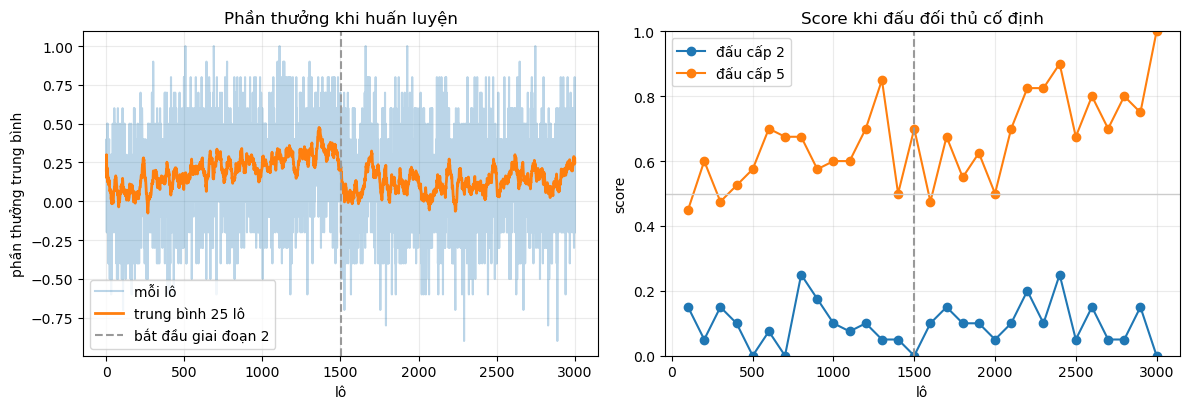

In [4]:
def rolling_mean(values, window):
    result = []
    for i in range(len(values)):
        start = max(0, i - window + 1)
        result.append(float(np.mean(values[start:i + 1])))
    return result

stage1 = report["stage1"]
stage2 = report["stage2"]
n1 = len(stage1["batch"])
rewards = stage1["mean_reward"] + stage2["mean_reward"]
batches = list(range(1, len(rewards) + 1))

eval_x = []
eval_cap2 = []
eval_cap5 = []
for item in stage1["eval"]:
    eval_x.append(item["batch"])
    eval_cap2.append(item["scores"]["cap2"])
    eval_cap5.append(item["scores"]["cap5"])
for item in stage2["eval"]:
    eval_x.append(n1 + item["batch"])
    eval_cap2.append(item["scores"]["cap2"])
    eval_cap5.append(item["scores"]["cap5"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(batches, rewards, alpha=0.3, label="mỗi lô")
axes[0].plot(batches, rolling_mean(rewards, 25), linewidth=2, label="trung bình 25 lô")
axes[0].axvline(n1 + 0.5, color="#999999", linestyle="--", label="bắt đầu giai đoạn 2")
axes[0].set_xlabel("lô")
axes[0].set_ylabel("phần thưởng trung bình")
axes[0].set_title("Phần thưởng khi huấn luyện")
axes[1].plot(eval_x, eval_cap2, marker="o", label="đấu cấp 2")
axes[1].plot(eval_x, eval_cap5, marker="o", label="đấu cấp 5")
axes[1].axvline(n1 + 0.5, color="#999999", linestyle="--")
axes[1].axhline(0.5, color="#cccccc", linewidth=1)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("lô")
axes[1].set_ylabel("score")
axes[1].set_title("Score khi đấu đối thủ cố định")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(ex.fig("nb4_duong_cong_pg.png"), dpi=150)

## 4. RQ2: cấp 6 so với cấp 5

Cấp 6 đấu trực tiếp cấp 5, và cả hai cùng đấu một bộ đối thủ chung (cấp 1–4).
Cả cấp 5 và 6 đều tất định nên mỗi ván mở đầu bằng 2 nước ngẫu nhiên có seed (`rq2.opening_random_moves`).

In [5]:
rq2_cfg = cfg["rq2"]
n_games = ex.n(rq2_cfg["games_per_pair"], 6)
opening = rq2_cfg["opening_random_moves"]
log_path = ex.log("nb4_rq2.jsonl")

cap5 = with_random_opening(ex.agent("cap5"), opening)
cap6 = with_random_opening(ex.agent("cap6"), opening)

rq2_summaries = []
s = run_match(cap6, cap5, "cap6", "cap5", n_games, seed=rq2_cfg["seed"], log_path=log_path)
rq2_summaries.append(s)
print(format_summary(s))

k = 1
for name in rq2_cfg["opponents"]:
    opponent = with_random_opening(ex.agent(name), opening)
    for learner_name, learner in [("cap5", cap5), ("cap6", cap6)]:
        s = run_match(learner, opponent, learner_name, name, n_games, seed=rq2_cfg["seed"] + k, log_path=log_path)
        rq2_summaries.append(s)
        print(format_summary(s))
        k += 1

rq2_table = summaries_table(rq2_summaries)
rq2_table.to_csv(ex.table("nb4_rq2.csv"), index=False, encoding="utf-8-sig")
rq2_table

cap6 vs cap5: 145-6-49 (thắng-hòa-thua), score 0.740 [0.675, 0.796], thời gian TB 1.4 ms, p95 2.2 ms


cap5 vs cap1: 170-0-30 (thắng-hòa-thua), score 0.850 [0.794, 0.893], thời gian TB 1.3 ms, p95 2.3 ms


cap6 vs cap1: 166-0-34 (thắng-hòa-thua), score 0.830 [0.772, 0.876], thời gian TB 1.3 ms, p95 2.1 ms


cap5 vs cap2: 26-0-174 (thắng-hòa-thua), score 0.130 [0.090, 0.184], thời gian TB 1.4 ms, p95 2.4 ms


cap6 vs cap2: 18-1-181 (thắng-hòa-thua), score 0.092 [0.060, 0.141], thời gian TB 1.5 ms, p95 2.6 ms


cap5 vs cap3: 16-49-135 (thắng-hòa-thua), score 0.203 [0.153, 0.264], thời gian TB 1.7 ms, p95 2.5 ms


cap6 vs cap3: 7-0-193 (thắng-hòa-thua), score 0.035 [0.017, 0.070], thời gian TB 1.7 ms, p95 2.5 ms


cap5 vs cap4: 8-1-191 (thắng-hòa-thua), score 0.043 [0.022, 0.080], thời gian TB 1.8 ms, p95 3.0 ms


cap6 vs cap4: 3-1-196 (thắng-hòa-thua), score 0.018 [0.006, 0.047], thời gian TB 1.9 ms, p95 3.0 ms


,tác tử,đối thủ,số ván,thắng,hòa,thua,score,Wilson 95%,TB (ms),p95 (ms),xử thua
0,cap6,cap5,200,145,6,49,0.740,"[0.675, 0.796]",1.4,2.2,0
1,cap5,cap1,200,170,0,30,0.850,"[0.794, 0.893]",1.3,2.3,0
2,cap6,cap1,200,166,0,34,0.830,"[0.772, 0.876]",1.3,2.1,0
3,cap5,cap2,200,26,0,174,0.130,"[0.090, 0.184]",1.4,2.4,0
4,cap6,cap2,200,18,1,181,0.092,"[0.060, 0.141]",1.5,2.6,0
5,cap5,cap3,200,16,49,135,0.203,"[0.153, 0.264]",1.7,2.5,0
6,cap6,cap3,200,7,0,193,0.035,"[0.017, 0.070]",1.7,2.5,0
7,cap5,cap4,200,8,1,191,0.043,"[0.022, 0.080]",1.8,3.0,0
8,cap6,cap4,200,3,1,196,0.018,"[0.006, 0.047]",1.9,3.0,0


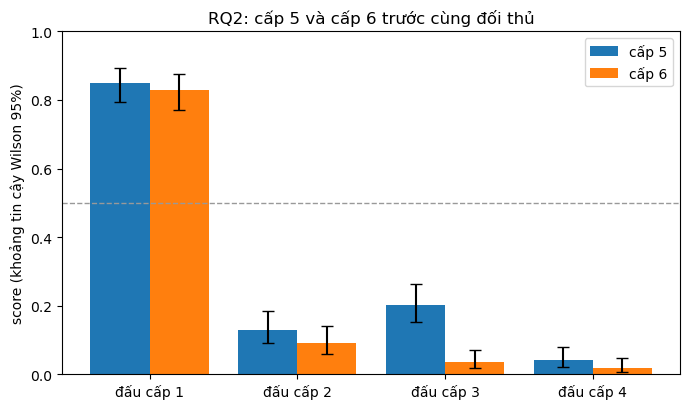

In [6]:
# Score của cấp 5 và cấp 6 trước cùng một đối thủ
opponents = rq2_cfg["opponents"]
score5 = []
score6 = []
for name in opponents:
    for s in rq2_summaries:
        if s["opponent"] == name and s["agent"] == "cap5":
            score5.append(s)
        if s["opponent"] == name and s["agent"] == "cap6":
            score6.append(s)

x = np.arange(len(opponents))
fig, ax = plt.subplots(figsize=(7, 4.2))
for offset, label, series in [(-0.2, "cấp 5", score5), (0.2, "cấp 6", score6)]:
    scores = [s["score"] for s in series]
    low = [max(0.0, s["score"] - s["ci_low"]) for s in series]
    high = [max(0.0, s["ci_high"] - s["score"]) for s in series]
    ax.bar(x + offset, scores, width=0.4, yerr=[low, high], capsize=4, label=label)
ax.set_xticks(x, ["đấu " + name.replace("cap", "cấp ") for name in opponents])
ax.set_ylim(0, 1)
ax.axhline(0.5, color="#999999", linestyle="--", linewidth=1)
ax.set_ylabel("score (khoảng tin cậy Wilson 95%)")
ax.set_title("RQ2: cấp 5 và cấp 6 trước cùng đối thủ")
ax.legend()
fig.tight_layout()
fig.savefig(ex.fig("nb4_rq2.png"), dpi=150)

In [7]:
tactics_path = ex.model("tactics.json")
if os.path.exists(tactics_path):
    positions = tactics.load_tactics(tactics_path)
    rows = []
    for name in ["cap5", "cap6"]:
        move_fn, info_fn = ex.agent(name)
        row = {"tác tử": name}
        row.update(tactics.score_agent(move_fn, positions))
        rows.append(row)
    rq2_tactics = pd.DataFrame(rows).round(3)
    rq2_tactics.to_csv(ex.table("nb4_chien_thuat_cap5_6.csv"), index=False, encoding="utf-8-sig")
    display(rq2_tactics)
else:
    print("Chưa có", tactics_path, "- chạy mục 1 của nb2 (hoặc chép file từ máy kia) rồi chạy lại ô này.")

,tác tử,win_now,must_block,double_threat,all
0,cap5,0.143,0.462,0.308,0.300
1,cap6,0.286,0.385,0.308,0.325
